
# Building a convolutional neural network for a quick-commerce catalog

---

## The business problem

You run the catalog team at a quick-commerce app — the kind that promises grocery
delivery in ten minutes. Stock arrives at a dark store all day long, and a staff member
photographs each incoming product on their phone so it can be listed.

Someone then has to say **what that photograph is of**. Right now a human does it, and:

- **It does not scale.** Thousands of items a day across hundreds of dark stores.
- **It is inconsistent.** One person tags a carton "Milk", another "Dairy".
- **Mistakes are expensive.** A mis-tagged product is invisible in search and in the
  category a shopper is browsing. It simply does not sell.

So: **can we look at the photograph and name the product ourselves?**

That is image classification, and it is what we build today — from an empty file to a
working model you could put behind an API.

---

## What makes this notebook different

Almost every step produces a **picture**. You will see the raw photographs, the numbers
behind them, what the network does to them at each layer, what it learned, where it
fails, and how confident it is. If you only look at the images and skip the code, you
should still follow the whole argument.

**Runtime:** roughly 5 minutes on a laptop. **Downloads:** none for the main model.

> ### About the data
>
> These are real photographs from the **Grocery Store Dataset** (Klasson, Zhang &
> Kjellström), collected by walking through Swedish grocery stores with a phone camera.
> Natural lighting, awkward angles, hands in frame — exactly what your dark-store staff
> would produce.
>
> They ship with this notebook as `catalog_products.npz` (16 MB): 3,142 colour
> photographs across 10 product categories. Nothing to download.
>
> Source: <https://github.com/marcusklasson/GroceryStoreDataset> (MIT licence)
>
> The *seller tags*, *prices* and *cost figures* later on are **simulated by this
> notebook** with a fixed seed, since the dataset does not include them. Everything
> else is real.

## 0. Setup

In [ ]:
import io, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from PIL import Image

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# a small consistent palette, used throughout
MAROON, SLATE, TEAL, AMBER, GREY = "#8C1515", "#2F4858", "#0E6E5C", "#C97B12", "#B9BFC4"
plt.rcParams.update({"figure.dpi": 100, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})

print(f"torch {torch.__version__}  |  device {DEVICE}")

torch 2.11.0+cu130  |  device cuda


## 1. Load the catalog

The photographs are stored as JPEGs packed into one file. We decode them into arrays.

Each image becomes a block of numbers shaped **96 x 96 x 3** — ninety-six rows,
ninety-six columns, and 3 colour channels (red, green, blue).

In [ ]:
data = np.load("catalog_products.npz")
blob, offsets = data["jpeg_blob"], data["offsets"]
labels, split = data["labels"], data["split"]
CATEGORIES = [str(c) for c in data["classes"]]
DISPLAY_SIZE = int(data["size"][0])

def decode(i, size=None):
    """Decode product i back into an (H, W, 3) uint8 array."""
    img = Image.open(io.BytesIO(blob[offsets[i]:offsets[i+1]].tobytes()))
    if size: img = img.resize((size, size), Image.LANCZOS)
    return np.asarray(img, dtype=np.uint8)

images = np.stack([decode(i) for i in range(len(labels))])

tr, va, te = (np.where(split == k)[0] for k in (0, 1, 2))
print(f"{'Training photographs':<24}{len(tr):>6,}")
print(f"{'Validation photographs':<24}{len(va):>6,}")
print(f"{'Test photographs':<24}{len(te):>6,}")
print(f"{'Categories':<24}{len(CATEGORIES):>6}")
print(f"\nOne image is an array of shape {images[0].shape}  "
      f"= {images[0].size:,} numbers, each 0-255")

Training photographs     2,195
Validation photographs     309
Test photographs           638
Categories                  10

One image is an array of shape (96, 96, 3)  = 27,648 numbers, each 0-255


### Look at the products

Before any modelling — what are we actually dealing with?

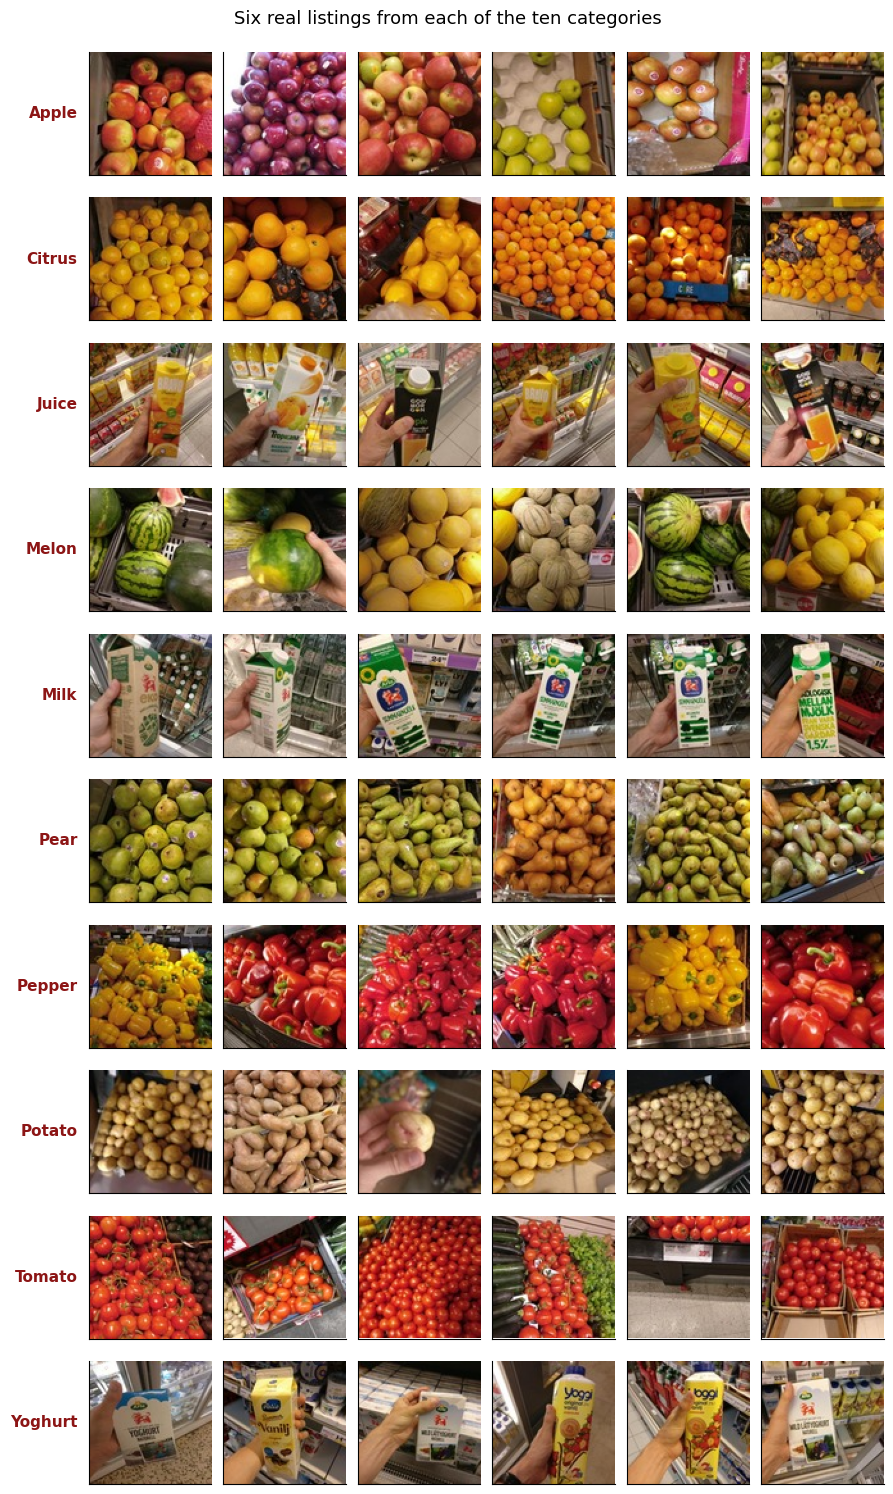

In [ ]:
fig, axes = plt.subplots(10, 6, figsize=(9, 15))
for c in range(10):
    idx = [i for i in tr if labels[i] == c][:6]
    for k in range(6):
        ax = axes[c, k]
        ax.imshow(images[idx[k]]); ax.set_xticks([]); ax.set_yticks([])
        if k == 0:
            ax.set_ylabel(CATEGORIES[c], rotation=0, ha="right", va="center",
                          fontsize=11, color=MAROON, fontweight="bold", labelpad=8)
fig.suptitle("Six real listings from each of the ten categories", y=0.995, fontsize=13)
plt.tight_layout()
plt.show()

Note what you are up against, because it decides everything that follows.

**Apple, Pear and Tomato** are all round and red-to-green. **Milk, Juice and Yoghurt**
are all rectangular cartons. Shape alone will not separate these — the network will have
to use colour, texture and packaging detail. When we read the confusion matrix later,
this is exactly where the mistakes will be.

Also notice the photographs themselves: hands, shelves, price tags, tilted angles,
different lighting. This is not a clean studio catalog. It is what real operations look
like.

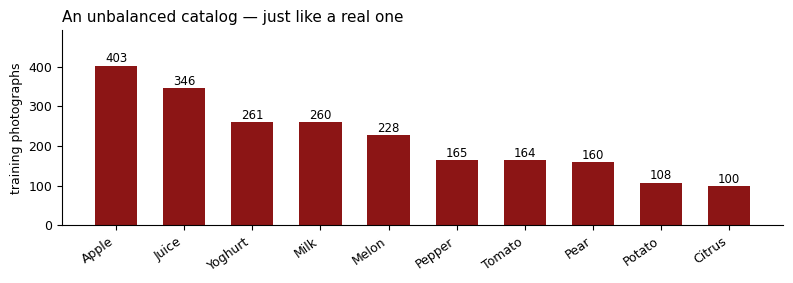

Most common category is Apple with 403 photographs; rarest is Citrus with 100.
Always guessing 'Apple' would score 18.2% on the test set.


In [ ]:
counts = np.bincount(labels[tr], minlength=10)
order = np.argsort(-counts)

fig, ax = plt.subplots(figsize=(8, 2.9))
bars = ax.bar([CATEGORIES[i] for i in order], counts[order], color=MAROON, width=0.62)
ax.set_ylabel("training photographs")
ax.set_ylim(0, counts.max() * 1.22)
ax.tick_params(axis="x", rotation=35)
for l in ax.get_xticklabels(): l.set_ha("right")
for b, v in zip(bars, counts[order]):
    ax.text(b.get_x() + b.get_width()/2, v + 8, str(v), ha="center", fontsize=8.5)
ax.set_title("An unbalanced catalog — just like a real one", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

print(f"Most common category is {len(CATEGORIES[order[0]]) * ''}{CATEGORIES[order[0]]} "
      f"with {counts[order[0]]} photographs; "
      f"rarest is {CATEGORIES[order[-1]]} with {counts[order[-1]]}.")
print(f"Always guessing '{CATEGORIES[np.argmax(counts)]}' would score "
      f"{np.bincount(labels[te], minlength=10)[np.argmax(counts)] / len(te):.1%} on the test set.")

This is our real baseline. Not 10% — the catalog is unbalanced, so a lazy model that
always guesses the most common category already scores better than chance. **Any model
we build has to beat that number to be worth deploying.**

## 2. What the computer actually sees

A photograph feels like a single thing to you. To the computer it is three stacked grids
of numbers — one for red, one for green, one for blue — and nothing else.

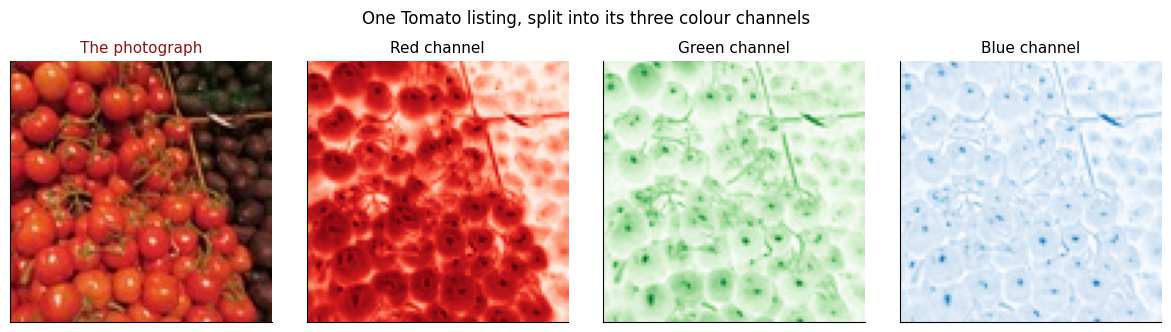

In [ ]:
demo = int([i for i in tr if CATEGORIES[labels[i]] == "Tomato"][0])
img = images[demo]

fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
axes[0].imshow(img); axes[0].set_title("The photograph", fontsize=11, color=MAROON)
for k, (name, cmap) in enumerate([("Red channel", "Reds"),
                                  ("Green channel", "Greens"),
                                  ("Blue channel", "Blues")]):
    axes[k+1].imshow(img[:, :, k], cmap=cmap, vmin=0, vmax=255)
    axes[k+1].set_title(name, fontsize=11)
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"One {CATEGORIES[labels[demo]]} listing, split into its three colour channels",
             y=1.02, fontsize=12)
plt.tight_layout(); plt.show()

The tomato is bright in the **red** channel and dark in the **green** and **blue** ones.
That is not a metaphor — it is literally three tables of numbers, and the difference
between them is what "red" means to a computer.

Now zoom all the way in until you can read the numbers themselves.

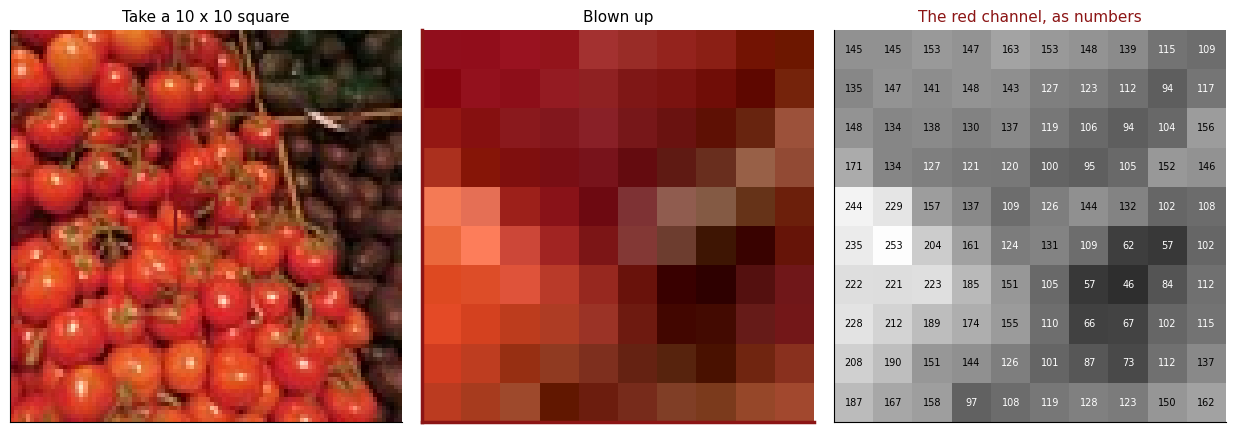

That little square alone is 10x10x3 = 300 numbers.
The whole photograph is 27,648 numbers.


In [ ]:
y0, x0, s = 40, 40, 10
patch = img[y0:y0+s, x0:x0+s]

fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.2))
axes[0].imshow(img); axes[0].set_xticks([]); axes[0].set_yticks([])
axes[0].add_patch(Rectangle((x0, y0), s, s, ec=MAROON, fc="none", lw=2.5))
axes[0].set_title("Take a 10 x 10 square", fontsize=11)

axes[1].imshow(patch); axes[1].set_xticks([]); axes[1].set_yticks([])
for sp in axes[1].spines.values(): sp.set_edgecolor(MAROON); sp.set_linewidth(2.5)
axes[1].set_title("Blown up", fontsize=11)

axes[2].imshow(patch[:, :, 0], cmap="gray", vmin=0, vmax=255)
for i in range(s):
    for j in range(s):
        v = patch[i, j, 0]
        axes[2].text(j, i, str(v), ha="center", va="center", fontsize=7,
                     color="black" if v > 128 else "white")
axes[2].set_xticks([]); axes[2].set_yticks([])
axes[2].set_title("The red channel, as numbers", fontsize=11, color=MAROON)
plt.tight_layout(); plt.show()

print(f"That little square alone is {s}x{s}x3 = {s*s*3} numbers.")
print(f"The whole photograph is {img.size:,} numbers.")

### How much resolution do we actually need?

Bigger images mean more numbers, which means slower training. Let us see how far we can
shrink a product photo before it stops being recognisable.

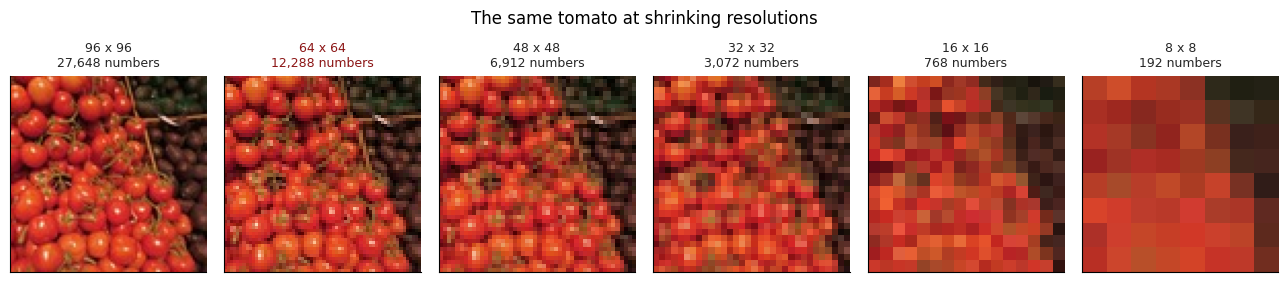

In [ ]:
sizes = [96, 64, 48, 32, 16, 8]
fig, axes = plt.subplots(1, len(sizes), figsize=(13, 2.6))
for ax, S in zip(axes, sizes):
    ax.imshow(np.asarray(Image.fromarray(img).resize((S, S), Image.LANCZOS)))
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{S} x {S}\n{S*S*3:,} numbers", fontsize=9,
                 color=MAROON if S == 64 else "#262626")
fig.suptitle("The same tomato at shrinking resolutions", y=1.06, fontsize=12)
plt.tight_layout(); plt.show()

At 16 x 16 it is a red blob; at 8 x 8 it is gone. **We will train at 64 x 64** — still
clearly a tomato, but a quarter of the numbers of the full image, which makes training
about four times faster. That trade-off is a real engineering decision, not a detail.

## 3. What do mistakes cost today?

Quantify the problem before you solve it. Otherwise you have no way of telling whether
the solution was worth building.

### What "manual tagging" means here

The process we are trying to replace is this: a staff member in the dark store
photographs an incoming product and picks its category from a dropdown on a handheld
scanner. They are working fast, often with one hand, and they are paid by throughput.

The dataset does not come with a record of anybody doing that, so **we simulate it.**
The simulation is deliberately simple and rests on three rules:

| | Rule | Value used below |
|---|---|---|
| **1** | Some products look alike and get mixed up far more often. We define two look-alike groups. | round produce = {Apple, Pear, Tomato}<br>cartons = {Milk, Juice, Yoghurt} |
| **2** | How often the worker slips at all. | **34%** for anything in a look-alike group, **14%** for everything else |
| **3** | When they do slip, what do they pick? Usually something from the same look-alike group — a tomato gets called an apple, not a potato. | a same-group category is **4x** more likely than any other |

We also attach a **price** to each category so that mistakes can be counted in rupees
rather than percentages. Prices are drawn around a plausible figure per product with 30%
variation.

> **These numbers are invented, not measured.** They are chosen to be realistic, and
> they are generated with a fixed seed so your output matches this notebook. Every
> figure that follows in this section inherits that assumption.
>
> **If you have a real catalog**, this is the one cell to replace. Load your own
> `manual_tag` and `price` columns from an export and everything downstream — the
> cost estimate, the confidence threshold, the review-queue sizing — keeps working
> unchanged.

In [ ]:
rng = np.random.default_rng(SEED)
y_test = labels[te]

# ---- SIMULATED manual tagging ---------------------------------------------------
ROUND   = {CATEGORIES.index(c) for c in ["Apple", "Pear", "Tomato"] if c in CATEGORIES}
CARTON  = {CATEGORIES.index(c) for c in ["Milk", "Juice", "Yoghurt"] if c in CATEGORIES}
GROUPS  = [ROUND, CARTON]

err_rate = np.array([0.34 if any(c in g for g in GROUPS) else 0.14 for c in range(10)])
manual_tag = y_test.copy()
for i in np.where(rng.random(len(y_test)) < err_rate[y_test])[0]:
    true_c = y_test[i]
    same = next((g for g in GROUPS if true_c in g), set())
    choices = [c for c in range(10) if c != true_c]
    w = np.array([4.0 if c in same else 1.0 for c in choices])
    manual_tag[i] = rng.choice(choices, p=w / w.sum())

BASE_PRICE = np.array([180, 150, 120, 260, 65, 210, 190, 55, 90, 85])
price = np.maximum(20, rng.normal(BASE_PRICE[y_test], BASE_PRICE[y_test] * 0.3)).round()
# --------------------------------------------------------------------------------

manual_acc = (manual_tag == y_test).mean()
print(f"Photographs in this batch      {len(y_test):,}")
print(f"Manual tag correct             {manual_acc:.1%}")
print(f"Tagged incorrectly             {(manual_tag != y_test).sum():,}")

Photographs in this batch      638
Manual tag correct             71.2%
Tagged incorrectly             184


### What one of those mistakes actually looks like

The percentages above are abstract. Let us pull a real example out of each look-alike
group — one round product and one carton that the simulated worker got wrong — and see
what the damage is in each case.

Re-run this cell to draw a different pair.

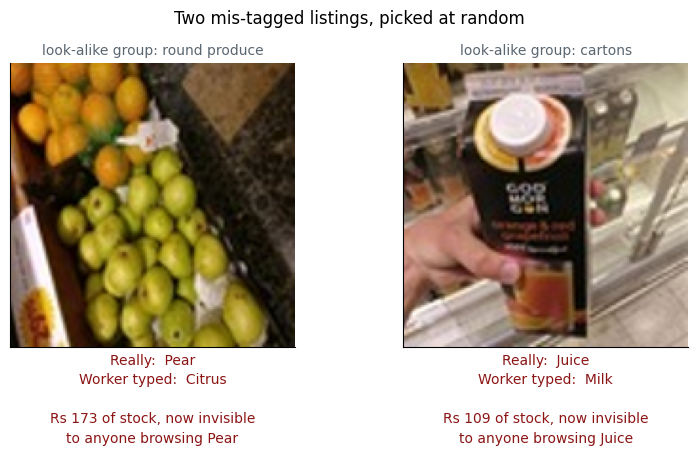

Pear      tagged as Citrus    (both are round produce)   Rs 173
Juice     tagged as Milk      (both are cartons)   Rs 109


In [ ]:
demo_rng = np.random.default_rng()          # unseeded: a new pair every run
mistagged = np.where(manual_tag != y_test)[0]

picks = []
for gname, group in [("round produce", ROUND), ("cartons", CARTON)]:
    pool = [i for i in mistagged if y_test[i] in group]
    if pool:
        picks.append((gname, int(demo_rng.choice(pool))))

fig, axes = plt.subplots(1, len(picks), figsize=(4.0 * len(picks), 4.2))
axes = np.atleast_1d(axes)
for ax, (gname, i) in zip(axes, picks):
    ax.imshow(np.asarray(Image.fromarray(decode(te[i])).resize((150, 150))))
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"look-alike group: {gname}", fontsize=10, color="#5A6670")
    ax.set_xlabel(
        f"Really:  {CATEGORIES[y_test[i]]}\n"
        f"Worker typed:  {CATEGORIES[manual_tag[i]]}\n\n"
        f"Rs {price[i]:,.0f} of stock, now invisible\n"
        f"to anyone browsing {CATEGORIES[y_test[i]]}",
        fontsize=10, color=MAROON, linespacing=1.5)
fig.suptitle("Two mis-tagged listings, picked at random", y=1.02, fontsize=12)
plt.tight_layout(); plt.show()

for gname, i in picks:
    print(f"{CATEGORIES[y_test[i]]:<9} tagged as {CATEGORIES[manual_tag[i]]:<9} "
          f"(both are {gname})   Rs {price[i]:,.0f}")

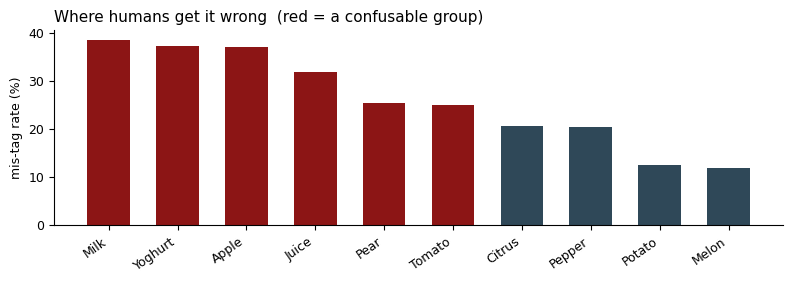

In [ ]:
per_class_err = np.array([(manual_tag[y_test == c] != c).mean() for c in range(10)])
o = np.argsort(-per_class_err)
cols = [MAROON if any(c in g for g in GROUPS) else SLATE for c in o]

fig, ax = plt.subplots(figsize=(8, 2.9))
ax.bar([CATEGORIES[c] for c in o], per_class_err[o] * 100, color=cols, width=0.62)
ax.set_ylabel("mis-tag rate (%)")
ax.tick_params(axis="x", rotation=35)
for l in ax.get_xticklabels(): l.set_ha("right")
ax.set_title("Where humans get it wrong  (red = a confusable group)",
             loc="left", fontsize=11)
plt.tight_layout(); plt.show()

In [ ]:
VISIBILITY_LOSS, CONVERSION = 0.60, 0.05
def gmv_lost(tags):
    return price[tags != y_test].sum() * VISIBILITY_LOSS * CONVERSION

base_loss = gmv_lost(manual_tag)
print(f"Value sitting in the wrong category   Rs {price[manual_tag != y_test].sum():>10,.0f}")
print(f"Estimated sales lost, this batch      Rs {base_loss:>10,.0f}")
print(f"Per photograph                        Rs {base_loss/len(y_test):>10,.2f}")
print(f"Annualised at 30,000 listings a week  Rs {base_loss/len(y_test)*30_000*52:>10,.0f}")
print("\n(Rests entirely on the simulated tags and prices above.)")

Value sitting in the wrong category   Rs     23,584
Estimated sales lost, this batch      Rs        708
Per photograph                        Rs       1.11
Annualised at 30,000 listings a week  Rs  1,729,986

(Rests entirely on the simulated tags and prices above.)


## 4. Prepare the photographs for the network

Three steps, each with a visible effect:

1. **Resize to 64 x 64** — the trade-off we decided in section 2.
2. **Scale the numbers from 0-255 down to 0-1** — networks train far more stably on
   small numbers. The picture does not change; only the scale on the axis does.
3. **Rearrange to (channels, height, width)** — PyTorch's expected order.

In [ ]:
TRAIN_SIZE = 64

def build(idx):
    X = np.stack([decode(i, TRAIN_SIZE) for i in idx]).astype(np.float32) / 255.0
    X = torch.tensor(X).permute(0, 3, 1, 2)          # (N, 3, 64, 64)
    return X, torch.tensor(labels[idx], dtype=torch.long)

Xtr, ytr = build(tr)
Xva, yva = build(va)
Xte, yte = build(te)

BATCH = 64
g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=BATCH, shuffle=True, generator=g)
val_loader   = DataLoader(TensorDataset(Xva, yva), batch_size=256)
test_loader  = DataLoader(TensorDataset(Xte, yte), batch_size=256)

print(f"Training tensor {tuple(Xtr.shape)}   values now in "
      f"[{Xtr.min():.2f}, {Xtr.max():.2f}]")
print(f"Batches per epoch: {len(train_loader)}")

Training tensor (2195, 3, 64, 64)   values now in [0.00, 1.00]
Batches per epoch: 35


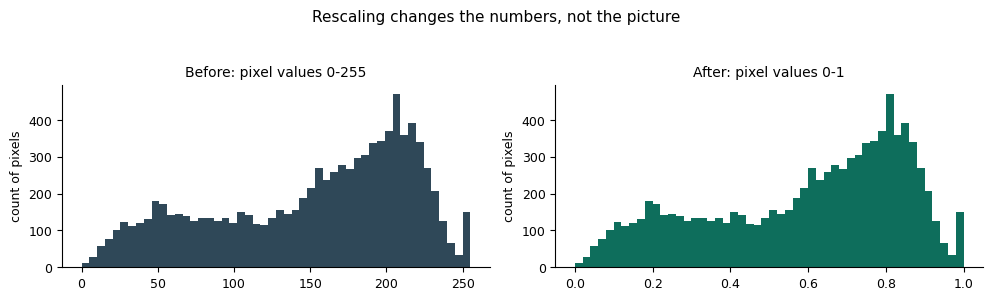

In [ ]:
raw = images[demo][:, :, 0].ravel()
scaled = (raw / 255.0)

fig, axes = plt.subplots(1, 2, figsize=(10, 2.8))
axes[0].hist(raw, bins=50, color=SLATE); axes[0].set_title("Before: pixel values 0-255", fontsize=10)
axes[1].hist(scaled, bins=50, color=TEAL); axes[1].set_title("After: pixel values 0-1", fontsize=10)
for ax in axes: ax.set_ylabel("count of pixels")
fig.suptitle("Rescaling changes the numbers, not the picture", y=1.05, fontsize=11)
plt.tight_layout(); plt.show()

### Data augmentation: making 2,195 photographs go further

We have only about two thousand training photographs, which is not many. But a tomato
photographed slightly rotated, or flipped, or a bit brighter, **is still a tomato**. We
can manufacture extra training examples for free by nudging the ones we have.

This is one of the highest-value tricks in computer vision, and it costs nothing.

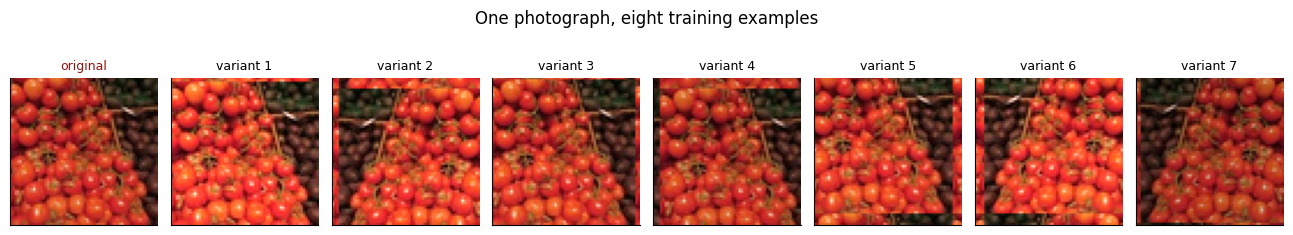

In [ ]:
def augment(batch):
    """Random horizontal flip, small shift, and brightness jitter."""
    out = batch.clone()
    flip = torch.rand(len(out)) < 0.5
    out[flip] = torch.flip(out[flip], dims=[3])
    shifts = torch.randint(-6, 7, (len(out), 2))
    for i, (dy, dx) in enumerate(shifts):
        out[i] = torch.roll(out[i], shifts=(int(dy), int(dx)), dims=(1, 2))
    out = torch.clamp(out * (0.75 + 0.5 * torch.rand(len(out), 1, 1, 1)), 0, 1)
    return out

torch.manual_seed(SEED)
one = Xtr[[int(np.where(tr == demo)[0][0])]] if demo in tr else Xtr[[0]]
variants = torch.cat([augment(one) for _ in range(7)])

fig, axes = plt.subplots(1, 8, figsize=(13, 2.1))
axes[0].imshow(one[0].permute(1, 2, 0).numpy())
axes[0].set_title("original", fontsize=9, color=MAROON)
for k in range(7):
    axes[k+1].imshow(variants[k].permute(1, 2, 0).numpy())
    axes[k+1].set_title(f"variant {k+1}", fontsize=9)
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("One photograph, eight training examples", y=1.10, fontsize=12)
plt.tight_layout(); plt.show()

> **A caution.** Augmentation must preserve the label. Flipping a tomato left-to-right is
> fine. Flipping a photograph of the *letter* R is not, and flipping a left shoe gives you
> a right shoe. Always ask whether your transformation could change the correct answer.

## 5. A training loop we can reuse

We train three different models, so write this once.

In [ ]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval(); loss_sum = correct = n = 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        out = model(xb)
        loss_sum += F.cross_entropy(out, yb, reduction="sum").item()
        correct  += (out.argmax(1) == yb).sum().item(); n += yb.size(0)
    return loss_sum / n, correct / n


def train(model, epochs=15, lr=1e-3, use_aug=True, quiet=False):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train_acc": [], "val_acc": [], "train_loss": [], "val_loss": []}
    for ep in range(1, epochs + 1):
        model.train(); loss_sum = correct = n = 0
        for xb, yb in train_loader:
            if use_aug: xb = augment(xb)
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            out = model(xb); loss = F.cross_entropy(out, yb)
            loss.backward(); opt.step()
            loss_sum += loss.item() * yb.size(0)
            correct  += (out.argmax(1) == yb).sum().item(); n += yb.size(0)
        vl, va_ = evaluate(model, val_loader)
        hist["train_loss"].append(loss_sum/n); hist["train_acc"].append(correct/n)
        hist["val_loss"].append(vl);           hist["val_acc"].append(va_)
        if not quiet:
            print(f"  epoch {ep:>2}/{epochs}   train acc {correct/n:.3f}   "
                  f"val acc {va_:.3f}   val loss {vl:.3f}")
    return hist

def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

## 6. Baseline: flatten the photograph and use a plain network

Recall the lecture. An ordinary feed-forward network cannot take a picture — it needs a
flat list. So we stretch the 64 x 64 x 3 block into a single row of 12,288 numbers and
throw away the fact that the image was ever two-dimensional.

In [ ]:
class FlatNet(nn.Module):
    """A conventional dense network on flattened pixels."""
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64*64*3, 256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, 128),     nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, 10))
    def forward(self, x): return self.net(x)

EPOCHS = 20
torch.manual_seed(SEED)
flat = FlatNet()
print(f"Dense network on flat pixels — {n_params(flat):,} parameters\n")
hist_flat = train(flat, epochs=EPOCHS)

Dense network on flat pixels — 3,180,170 parameters

  epoch  1/20   train acc 0.206   val acc 0.382   val loss 1.740
  epoch  2/20   train acc 0.319   val acc 0.417   val loss 1.509
  epoch  3/20   train acc 0.359   val acc 0.405   val loss 1.462
  epoch  4/20   train acc 0.382   val acc 0.450   val loss 1.369
  epoch  5/20   train acc 0.396   val acc 0.421   val loss 1.331
  epoch  6/20   train acc 0.408   val acc 0.450   val loss 1.265
  epoch  7/20   train acc 0.408   val acc 0.456   val loss 1.302
  epoch  8/20   train acc 0.436   val acc 0.453   val loss 1.307
  epoch  9/20   train acc 0.409   val acc 0.482   val loss 1.261
  epoch 10/20   train acc 0.430   val acc 0.502   val loss 1.225
  epoch 11/20   train acc 0.431   val acc 0.463   val loss 1.256
  epoch 12/20   train acc 0.429   val acc 0.485   val loss 1.213
  epoch 13/20   train acc 0.437   val acc 0.476   val loss 1.226
  epoch 14/20   train acc 0.462   val acc 0.550   val loss 1.153
  epoch 15/20   train acc 0.444   val

## 7. The convolutional network

Same three ingredients from the lecture, stacked three times:

> **convolution** to find patterns, **ReLU** to keep the strong ones, **pooling** to
> shrink and summarise.

One convolution layer per block. Nothing doubled up, nothing clever. The only thing that
changes from block to block is that the picture gets **smaller** while the number of
filters **doubles** — trading spatial detail for descriptive richness.

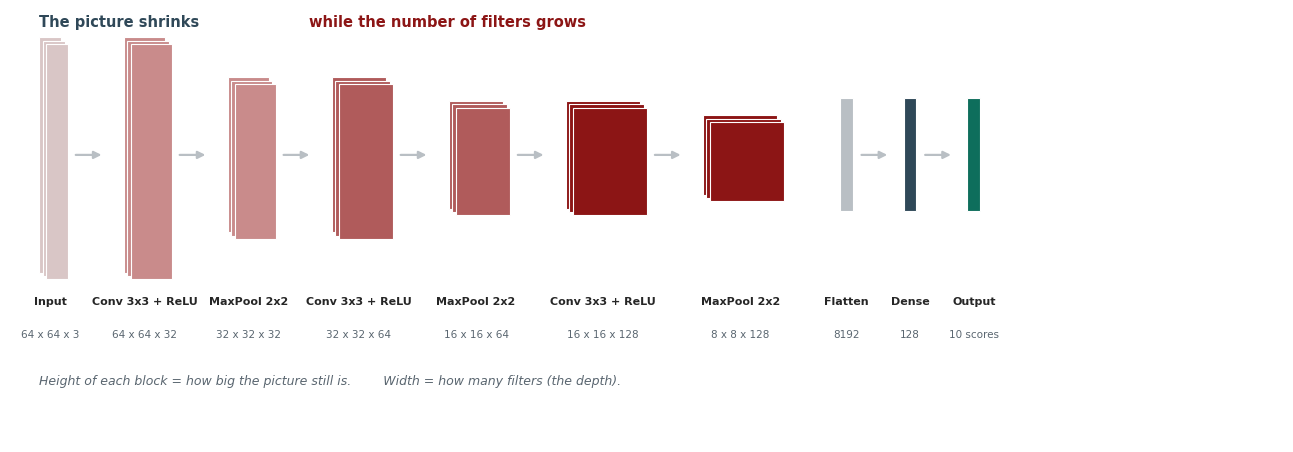

In [ ]:
def draw_architecture():
    """Draw the network as a diagram, the way it appears on a slide."""
    fig, ax = plt.subplots(figsize=(13, 4.6))
    ax.set_xlim(0, 13); ax.set_ylim(0, 4.6); ax.axis("off")
    CY, NAME_Y, SHAPE_Y = 3.05, 1.55, 1.20

    stages = [
        ("Input",          64, 3,   "#D9C6C6", "64 x 64 x 3"),
        ("Conv 3x3 + ReLU", 64, 32,  "#C98B8B", "64 x 64 x 32"),
        ("MaxPool 2x2",    32, 32,  "#C98B8B", "32 x 32 x 32"),
        ("Conv 3x3 + ReLU", 32, 64,  "#B05B5B", "32 x 32 x 64"),
        ("MaxPool 2x2",    16, 64,  "#B05B5B", "16 x 16 x 64"),
        ("Conv 3x3 + ReLU", 16, 128, "#8C1515", "16 x 16 x 128"),
        ("MaxPool 2x2",     8, 128, "#8C1515", "8 x 8 x 128"),
    ]
    x = 0.30
    for i, (name, side, depth, col, shape) in enumerate(stages):
        h = 0.40 + 2.10 * (side / 64) ** 0.75
        w = 0.16 + 0.60 * (depth / 128) ** 0.6
        y = CY - h / 2
        for k in range(3):
            ax.add_patch(Rectangle((x + k*0.035, y - k*0.035), w, h,
                                   fc=col, ec="white", lw=0.8))
        ax.text(x + w/2, NAME_Y, name, ha="center", va="top",
                fontsize=8, fontweight="bold", color="#262626")
        ax.text(x + w/2, SHAPE_Y, shape, ha="center", va="top",
                fontsize=7.5, color="#5A6670")
        if i < len(stages) - 1:
            ax.add_patch(FancyArrowPatch((x + w + 0.12, CY), (x + w + 0.44, CY),
                                         arrowstyle="-|>", mutation_scale=11,
                                         color=GREY, lw=1.6))
        x += w + 0.64

    for lbl, shape, col in [("Flatten", "8192", GREY),
                            ("Dense", "128", SLATE),
                            ("Output", "10 scores", TEAL)]:
        ax.add_patch(Rectangle((x, CY - 0.60), 0.13, 1.20, fc=col, ec="white", lw=0.8))
        ax.text(x + 0.065, NAME_Y, lbl, ha="center", va="top",
                fontsize=8, fontweight="bold", color="#262626")
        ax.text(x + 0.065, SHAPE_Y, shape, ha="center", va="top",
                fontsize=7.5, color="#5A6670")
        x += 0.13 + 0.52
        if lbl != "Output":
            ax.add_patch(FancyArrowPatch((x - 0.46, CY), (x - 0.14, CY),
                                         arrowstyle="-|>", mutation_scale=11,
                                         color=GREY, lw=1.6))

    ax.text(0.30, 4.42, "The picture shrinks", fontsize=10.5, color=SLATE, fontweight="bold")
    ax.text(3.05, 4.42, "while the number of filters grows",
            fontsize=10.5, color=MAROON, fontweight="bold")
    ax.text(0.30, 0.62, "Height of each block = how big the picture still is.        "
                        "Width = how many filters (the depth).",
            fontsize=9, color="#5A6670", style="italic")
    plt.tight_layout(); plt.show()

draw_architecture()

In [ ]:
class ProductCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.block1 = nn.Sequential(nn.Conv2d(3,   32,  3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.block2 = nn.Sequential(nn.Conv2d(32,  64,  3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.block3 = nn.Sequential(nn.Conv2d(64,  128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.head = nn.Sequential(
            nn.Flatten(), nn.Dropout(0.4),
            nn.Linear(128 * 8 * 8, 128), nn.ReLU(),
            nn.Dropout(0.4), nn.Linear(128, n_classes))

    def forward(self, x):
        return self.head(self.block3(self.block2(self.block1(x))))

torch.manual_seed(SEED)
cnn = ProductCNN()
print(cnn)
print(f"\nTotal parameters: {n_params(cnn):,}")

ProductCNN(
  (block1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.4, inplace=False)
    (2): Linear(in_features=8192, out_features=128, bias=True)
    (3): ReLU()
    (4): Dropout(p=0.4, inplace=False)
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)

Total parameters: 1,143,242


### Watch the shape change at every step

The diagram above, verified against the real tensors.

In [ ]:
x = Xtr[:1]
rows = [("input", tuple(x.shape[1:]))]
for name, blk in [("block1", cnn.block1), ("block2", cnn.block2), ("block3", cnn.block3)]:
    x = blk(x); rows.append((name, tuple(x.shape[1:])))
rows.append(("flatten", (int(np.prod(x.shape[1:])),)))

print(f"{'Stage':<10}{'Shape (C, H, W)':<22}{'Numbers':>12}")
print("-" * 45)
for name, shp in rows:
    print(f"{name:<10}{str(shp):<22}{int(np.prod(shp)):>12,}")

Stage     Shape (C, H, W)            Numbers
---------------------------------------------
input     (3, 64, 64)                 12,288
block1    (32, 32, 32)                32,768
block2    (64, 16, 16)                16,384
block3    (128, 8, 8)                  8,192
flatten   (8192,)                      8,192


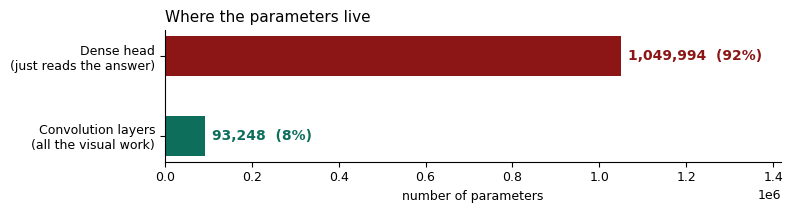

In [ ]:
conv_p = sum(p.numel() for m in cnn.modules() if isinstance(m, nn.Conv2d) for p in m.parameters())
head_p = sum(p.numel() for m in cnn.head.modules() if isinstance(m, nn.Linear) for p in m.parameters())

fig, ax = plt.subplots(figsize=(8, 2.2))
ax.barh(["Convolution layers\n(all the visual work)", "Dense head\n(just reads the answer)"],
        [conv_p, head_p], color=[TEAL, MAROON], height=0.5)
ax.set_xlabel("number of parameters")
for i, v in enumerate([conv_p, head_p]):
    ax.text(v + head_p*0.015, i, f"{v:,}  ({v/n_params(cnn):.0%})",
            va="center", fontsize=10, fontweight="bold",
            color=TEAL if i == 0 else MAROON)
ax.set_xlim(0, head_p * 1.35)
ax.set_title("Where the parameters live", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

Exactly the AlexNet observation from the lecture: **the convolutions do all the seeing
and hold almost none of the parameters.** A 3 x 3 filter is nine numbers whether it runs
on a thumbnail or a billboard, because the same nine numbers are reused everywhere.

## 8. Train it

In [ ]:
t0 = time.time()
print(f"Training ProductCNN for {EPOCHS} epochs on {DEVICE}\n")
hist_cnn = train(cnn, epochs=EPOCHS)
print(f"\nDone in {time.time() - t0:.0f} seconds")

Training ProductCNN for 20 epochs on cuda

  epoch  1/20   train acc 0.256   val acc 0.382   val loss 1.649
  epoch  2/20   train acc 0.385   val acc 0.492   val loss 1.390
  epoch  3/20   train acc 0.435   val acc 0.434   val loss 1.376
  epoch  4/20   train acc 0.471   val acc 0.612   val loss 1.065
  epoch  5/20   train acc 0.544   val acc 0.631   val loss 1.001
  epoch  6/20   train acc 0.605   val acc 0.702   val loss 0.820
  epoch  7/20   train acc 0.649   val acc 0.718   val loss 0.742
  epoch  8/20   train acc 0.659   val acc 0.780   val loss 0.705
  epoch  9/20   train acc 0.696   val acc 0.796   val loss 0.644
  epoch 10/20   train acc 0.725   val acc 0.803   val loss 0.598
  epoch 11/20   train acc 0.745   val acc 0.706   val loss 0.742
  epoch 12/20   train acc 0.757   val acc 0.819   val loss 0.549
  epoch 13/20   train acc 0.748   val acc 0.822   val loss 0.544
  epoch 14/20   train acc 0.769   val acc 0.809   val loss 0.593
  epoch 15/20   train acc 0.770   val acc 0.828

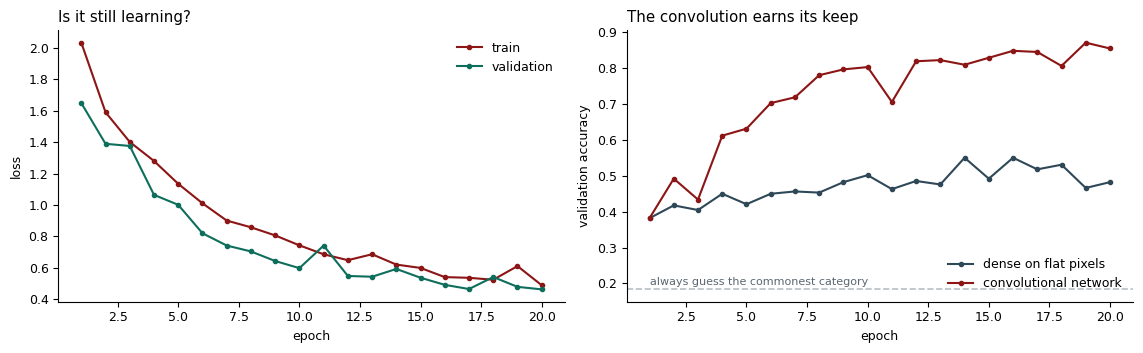

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6))
ep = range(1, EPOCHS + 1)

axes[0].plot(ep, hist_cnn["train_loss"], "-o", ms=3, color=MAROON, label="train")
axes[0].plot(ep, hist_cnn["val_loss"], "-o", ms=3, color=TEAL, label="validation")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss")
axes[0].set_title("Is it still learning?", loc="left"); axes[0].legend(frameon=False)

axes[1].plot(ep, hist_flat["val_acc"], "-o", ms=3, color=SLATE, label="dense on flat pixels")
axes[1].plot(ep, hist_cnn["val_acc"],  "-o", ms=3, color=MAROON, label="convolutional network")
axes[1].axhline(counts.max()/counts.sum(), color=GREY, ls="--", lw=1.2)
axes[1].text(1, counts.max()/counts.sum() + 0.012, "always guess the commonest category",
             fontsize=8, color="#5A6670")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("validation accuracy")
axes[1].set_title("The convolution earns its keep", loc="left")
axes[1].legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

## 9. Look inside: what happens at each block?

This is the part worth slowing down for. We push **one photograph** through the trained
network and look at what comes out of every stage.

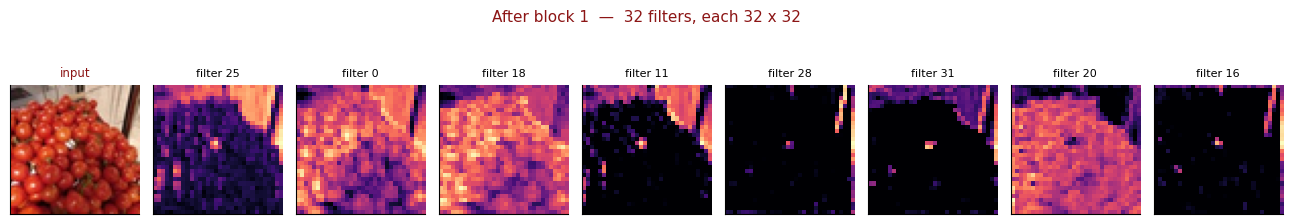

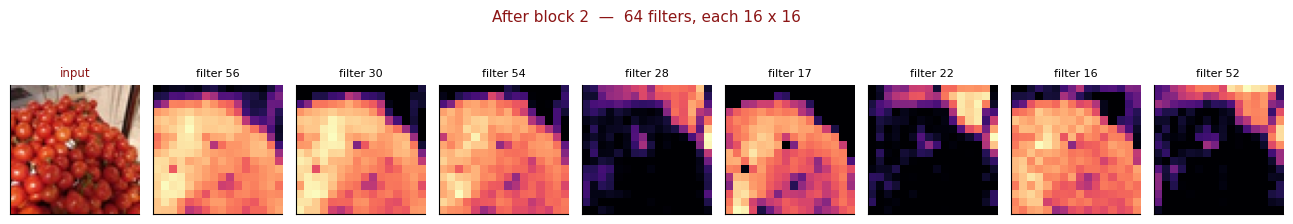

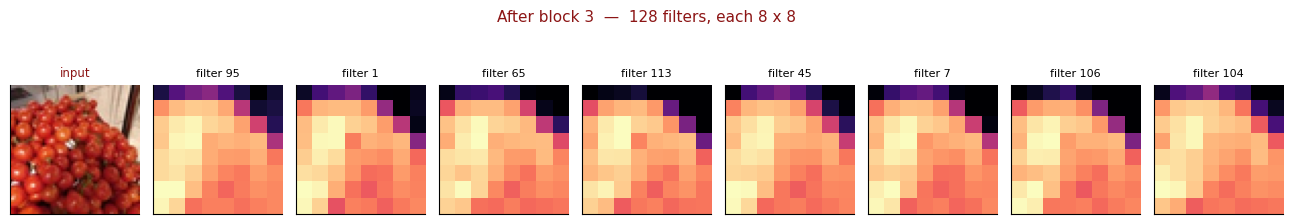

In [ ]:
probe_i = int(np.where(te == [i for i in te if CATEGORIES[labels[i]] == "Tomato"][0])[0][0])
probe = Xte[probe_i:probe_i+1].to(DEVICE)

cnn.eval()
with torch.no_grad():
    a1 = cnn.block1(probe)
    a2 = cnn.block2(a1)
    a3 = cnn.block3(a2)

for stage, act in [("After block 1", a1), ("After block 2", a2), ("After block 3", a3)]:
    fm = act[0].cpu().numpy()
    strongest = np.argsort(-fm.reshape(len(fm), -1).max(1))[:8]
    fig, axes = plt.subplots(1, 9, figsize=(13, 1.9))
    axes[0].imshow(probe[0].permute(1,2,0).cpu().numpy())
    axes[0].set_title("input", fontsize=8.5, color=MAROON)
    for k, f_i in enumerate(strongest):
        axes[k+1].imshow(fm[f_i], cmap="magma")
        axes[k+1].set_title(f"filter {f_i}", fontsize=8)
    for ax in axes: ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(f"{stage}  —  {fm.shape[0]} filters, each {fm.shape[1]} x {fm.shape[2]}",
                 y=1.16, fontsize=11, color=MAROON)
    plt.tight_layout(); plt.show()

Read those three strips top to bottom and you can watch the network think.

**Block 1** still looks like a tomato. The maps are 32 x 32 and you can see outlines,
bright spots and colour boundaries — simple, local things.

**Block 2** is 16 x 16 and already abstract. Blobs of activation, not a recognisable
object.

**Block 3** is 8 x 8. Each square covers a large part of the original photograph. Nothing
here looks like a tomato to you, but this is the representation the classifier actually
uses — and it works.

The picture gets smaller and less recognisable while becoming **more useful**. That is
the whole idea of a deep network in one figure.

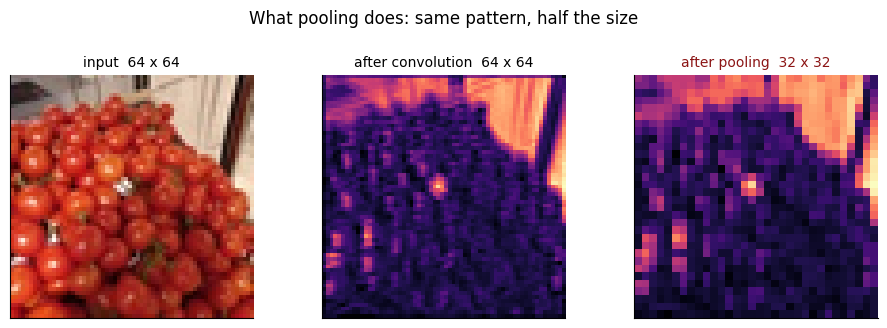

In [ ]:
with torch.no_grad():
    conv_only = F.relu(cnn.block1[0](probe))[0].cpu().numpy()
    pooled    = a1[0].cpu().numpy()

pick = int(np.argmax(conv_only.reshape(len(conv_only), -1).max(1)))
fig, axes = plt.subplots(1, 3, figsize=(9.5, 3.1))
axes[0].imshow(probe[0].permute(1,2,0).cpu().numpy()); axes[0].set_title("input  64 x 64", fontsize=10)
axes[1].imshow(conv_only[pick], cmap="magma");         axes[1].set_title("after convolution  64 x 64", fontsize=10)
axes[2].imshow(pooled[pick], cmap="magma");            axes[2].set_title("after pooling  32 x 32", fontsize=10, color=MAROON)
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("What pooling does: same pattern, half the size", y=1.04, fontsize=12)
plt.tight_layout(); plt.show()

### The filters it learned

Nobody wrote these. They are what gradient descent decided was worth looking for.

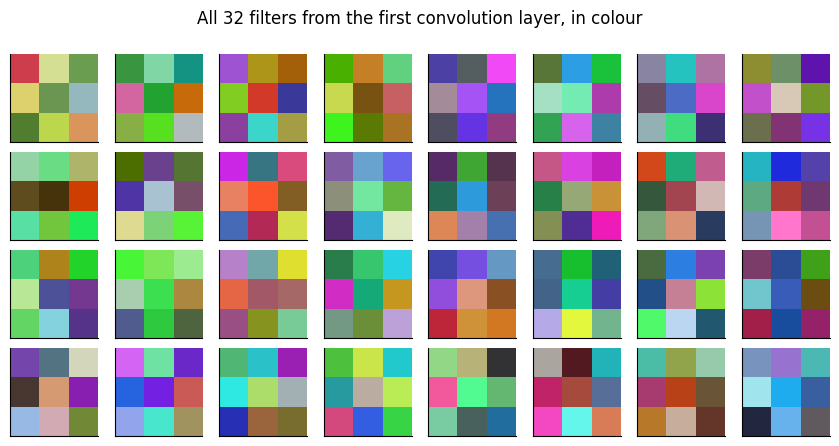

In [ ]:
W = cnn.block1[0].weight.detach().cpu().numpy()
Wn = (W - W.min()) / (W.max() - W.min())

fig, axes = plt.subplots(4, 8, figsize=(8.5, 4.4))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(Wn[i].transpose(1, 2, 0)); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("All 32 filters from the first convolution layer, in colour",
             y=1.00, fontsize=12)
plt.tight_layout(); plt.show()

Because our input is colour, each filter is a tiny 3 x 3 **colour** patch. Look for
red-versus-green tiles — those are the ones separating tomatoes from peppers. Others are
plain light-dark, which are edge detectors, exactly the shapes we drew by hand in the
lecture.

## 10. Evaluation

Now, and only now, we open the test set.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

@torch.no_grad()
def predict(model, X):
    model.eval(); out = []
    for i in range(0, len(X), 256):
        out.append(F.softmax(model(X[i:i+256].to(DEVICE)), dim=1).cpu())
    return torch.cat(out).numpy()

probs = predict(cnn, Xte)
pred, conf = probs.argmax(1), probs.max(1)

_, acc_flat = evaluate(flat, test_loader)
_, acc_cnn  = evaluate(cnn,  test_loader)
majority = np.bincount(labels[te], minlength=10)[np.argmax(counts)] / len(te)

print(f"{'Approach':<34}{'Test accuracy':>15}")
print("-" * 49)
print(f"{'Always guess commonest category':<34}{majority:>14.1%}")
print(f"{'Manual tagging (simulated)':<34}{manual_acc:>14.1%}")
print(f"{'Dense network on flat pixels':<34}{acc_flat:>14.1%}")
print(f"{'Convolutional network':<34}{acc_cnn:>14.1%}")

Approach                            Test accuracy
-------------------------------------------------
Always guess commonest category            18.2%
Manual tagging (simulated)                 71.2%
Dense network on flat pixels               48.4%
Convolutional network                      83.2%


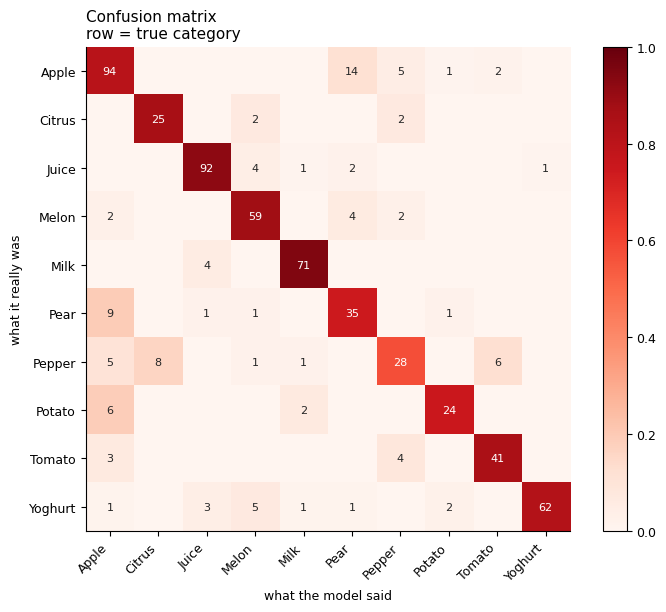

In [ ]:
cm = confusion_matrix(y_test, pred)
cmp_ = cm / cm.sum(1, keepdims=True)

fig, ax = plt.subplots(figsize=(7.4, 6.2))
im = ax.imshow(cmp_, cmap="Reds", vmin=0, vmax=1)
ax.set_xticks(range(10), CATEGORIES, rotation=45, ha="right")
ax.set_yticks(range(10), CATEGORIES)
ax.set_xlabel("what the model said"); ax.set_ylabel("what it really was")
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                    color="white" if cmp_[i, j] > 0.5 else "#262626")
ax.set_title("Confusion matrix\nrow = true category", loc="left", fontsize=11)
plt.colorbar(im, ax=ax, fraction=0.045)
plt.tight_layout(); plt.show()

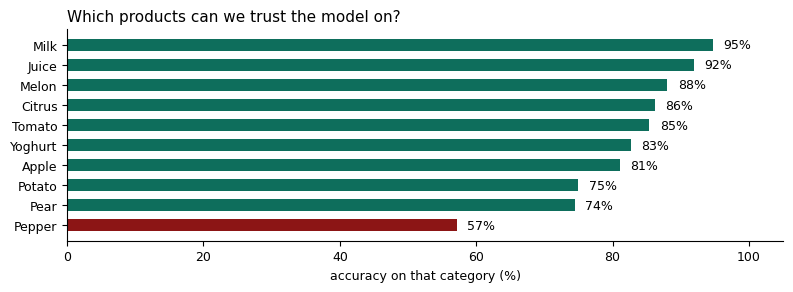

              precision    recall  f1-score   support

       Apple       0.78      0.81      0.80       116
      Citrus       0.76      0.86      0.81        29
       Juice       0.92      0.92      0.92       100
       Melon       0.82      0.88      0.85        67
        Milk       0.93      0.95      0.94        75
        Pear       0.62      0.74      0.68        47
      Pepper       0.68      0.57      0.62        49
      Potato       0.86      0.75      0.80        32
      Tomato       0.84      0.85      0.85        48
     Yoghurt       0.98      0.83      0.90        75

    accuracy                           0.83       638
   macro avg       0.82      0.82      0.82       638
weighted avg       0.84      0.83      0.83       638



In [ ]:
per_class = np.array([(pred[y_test == c] == c).mean() for c in range(10)])
o = np.argsort(per_class)
fig, ax = plt.subplots(figsize=(8, 3.0))
ax.barh([CATEGORIES[c] for c in o], per_class[o]*100,
        color=[MAROON if p < 0.7 else TEAL for p in per_class[o]], height=0.6)
ax.set_xlabel("accuracy on that category (%)"); ax.set_xlim(0, 105)
for i, c in enumerate(o):
    ax.text(per_class[c]*100 + 1.5, i, f"{per_class[c]:.0%}", va="center", fontsize=9)
ax.set_title("Which products can we trust the model on?", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

print(classification_report(y_test, pred, target_names=CATEGORIES, digits=2, zero_division=0))

In [ ]:
pairs = sorted(((cm[i,j], i, j) for i in range(10) for j in range(10) if i != j), reverse=True)
print("The model's most frequent mistakes")
print("-" * 52)
for n, i, j in pairs[:6]:
    print(f"{n:>3}  {CATEGORIES[i]:<10} was called  {CATEGORIES[j]}")

The model's most frequent mistakes
----------------------------------------------------
 14  Apple      was called  Pear
  9  Pear       was called  Apple
  8  Pepper     was called  Citrus
  6  Potato     was called  Apple
  6  Pepper     was called  Tomato
  5  Yoghurt    was called  Melon


## 11. Turning a model into a policy

91% or 78%, whatever we got — it is not yet a product. The real question is:

> **Which photographs do we tag automatically, and which go to a human?**

The network reports a probability for its top choice. If that confidence is meaningful,
we can auto-tag the confident ones and route the rest to a person.

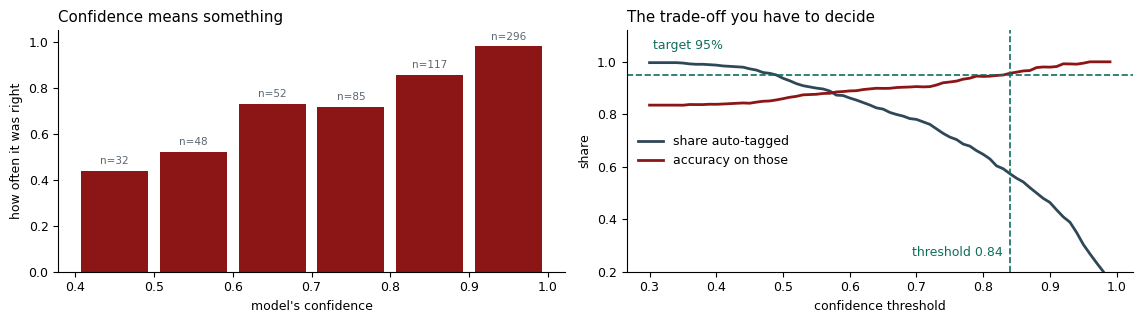

In [ ]:
edges = np.linspace(0.2, 1.0, 9)
mid, accs, ns = [], [], []
for a, b in zip(edges[:-1], edges[1:]):
    m = (conf >= a) & (conf < b)
    if m.sum() >= 15:
        mid.append((a+b)/2); accs.append((pred[m] == y_test[m]).mean()); ns.append(m.sum())

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.3))
axes[0].bar(mid, accs, width=0.085, color=MAROON)
axes[0].set_xlabel("model's confidence"); axes[0].set_ylabel("how often it was right")
axes[0].set_ylim(0, 1.05)
axes[0].set_title("Confidence means something", loc="left")
for x, a, n in zip(mid, accs, ns):
    axes[0].text(x, a + 0.03, f"n={n}", ha="center", fontsize=7.5, color="#5A6670")

ths = np.arange(0.30, 1.00, 0.01)
cov = np.array([(conf >= t).mean() for t in ths])
aacc = np.array([(pred[conf >= t] == y_test[conf >= t]).mean() if (conf >= t).sum() else np.nan
                 for t in ths])
TARGET = 0.95
ok = np.where(aacc >= TARGET)[0]
t_star = ths[ok[0]] if len(ok) else ths[int(np.nanargmax(aacc))]

axes[1].plot(ths, cov,  color=SLATE,  lw=2, label="share auto-tagged")
axes[1].plot(ths, aacc, color=MAROON, lw=2, label="accuracy on those")
axes[1].axhline(TARGET, color=TEAL, ls="--", lw=1.2)
axes[1].axvline(t_star, color=TEAL, ls="--", lw=1.2)
axes[1].set_ylim(0.2, 1.12)
axes[1].text(0.305, 1.05, f"target {TARGET:.0%}", color=TEAL, fontsize=9)
axes[1].text(t_star - 0.01, 0.26, f"threshold {t_star:.2f}", color=TEAL, fontsize=9, ha="right")
axes[1].set_xlabel("confidence threshold"); axes[1].set_ylabel("share")
axes[1].set_title("The trade-off you have to decide", loc="left")
axes[1].legend(frameon=False, loc="center left")
plt.tight_layout(); plt.show()

In [ ]:
auto = conf >= t_star
policy = np.where(auto, pred, y_test)     # humans fix the rest, assumed correct

print(f"Policy: auto-tag when confidence >= {t_star:.2f}")
print("-" * 58)
print(f"Auto-tagged          {auto.sum():>5,}  ({auto.mean():5.1%})   "
      f"accuracy {(pred[auto]==y_test[auto]).mean():.1%}")
print(f"Sent for review      {(~auto).sum():>5,}  ({(~auto).mean():5.1%})")
print()
print(f"{'Scenario':<34}{'Sales lost':>13}{'Recovered':>11}{'Reviewed':>10}")
print("-" * 68)
for name, tags, rev in [("Manual tagging today", manual_tag, len(y_test)),
                        ("Model tags everything", pred, 0),
                        (f"Model + review queue", policy, int((~auto).sum()))]:
    l = gmv_lost(tags)
    print(f"{name:<34}Rs{l:>11,.0f}{(base_loss-l)/base_loss:>11.0%}{rev:>10,}")

Policy: auto-tag when confidence >= 0.84
----------------------------------------------------------
Auto-tagged            366  (57.4%)   accuracy 95.6%
Sent for review        272  (42.6%)

Scenario                             Sales lost  Recovered  Reviewed
--------------------------------------------------------------------
Manual tagging today              Rs        708         0%       638
Model tags everything             Rs        481        32%         0
Model + review queue              Rs         82        88%       272


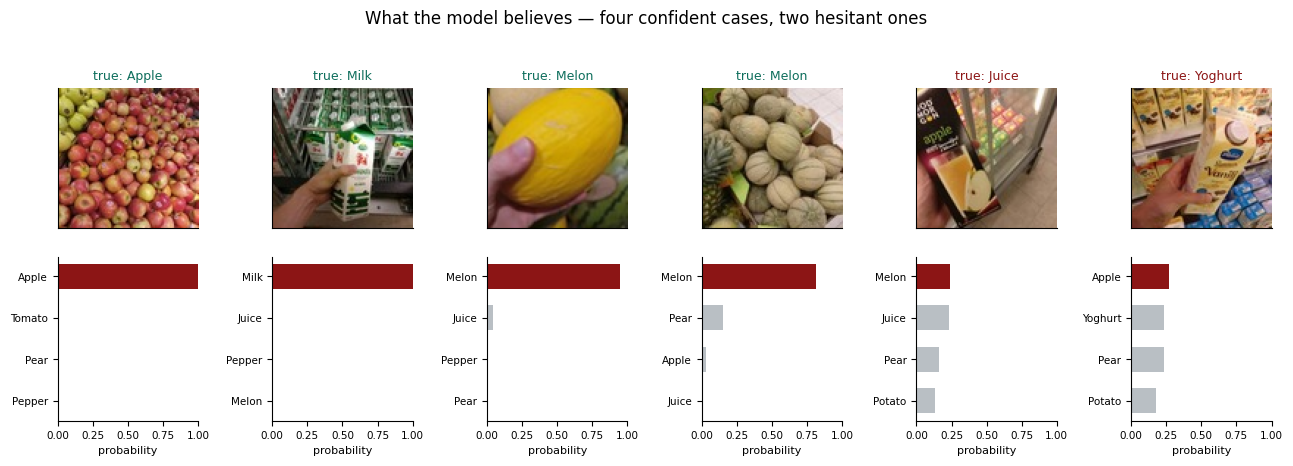

In [ ]:
show = np.argsort(-conf)[[0, 40, 200, 400]].tolist() + np.argsort(conf)[:2].tolist()
fig, axes = plt.subplots(2, 6, figsize=(13, 4.6),
                         gridspec_kw={"height_ratios": [1.25, 1]})
for k, i in enumerate(show):
    axes[0, k].imshow(np.asarray(Image.fromarray(decode(te[i])).resize((96, 96))))
    axes[0, k].set_xticks([]); ax = axes[0, k].set_yticks([])
    ok_ = pred[i] == y_test[i]
    axes[0, k].set_title(f"true: {CATEGORIES[y_test[i]]}", fontsize=9,
                         color=TEAL if ok_ else MAROON)
    top = np.argsort(-probs[i])[:4][::-1]
    axes[1, k].barh([CATEGORIES[t] for t in top], probs[i][top],
                    color=[MAROON if t == pred[i] else GREY for t in top], height=0.6)
    axes[1, k].set_xlim(0, 1); axes[1, k].tick_params(labelsize=7.5)
    axes[1, k].set_xlabel("probability", fontsize=8)
fig.suptitle("What the model believes — four confident cases, two hesitant ones",
             y=1.00, fontsize=12)
plt.tight_layout(); plt.show()

## 12. Where it fails

The confident mistakes are the ones that reach customers.

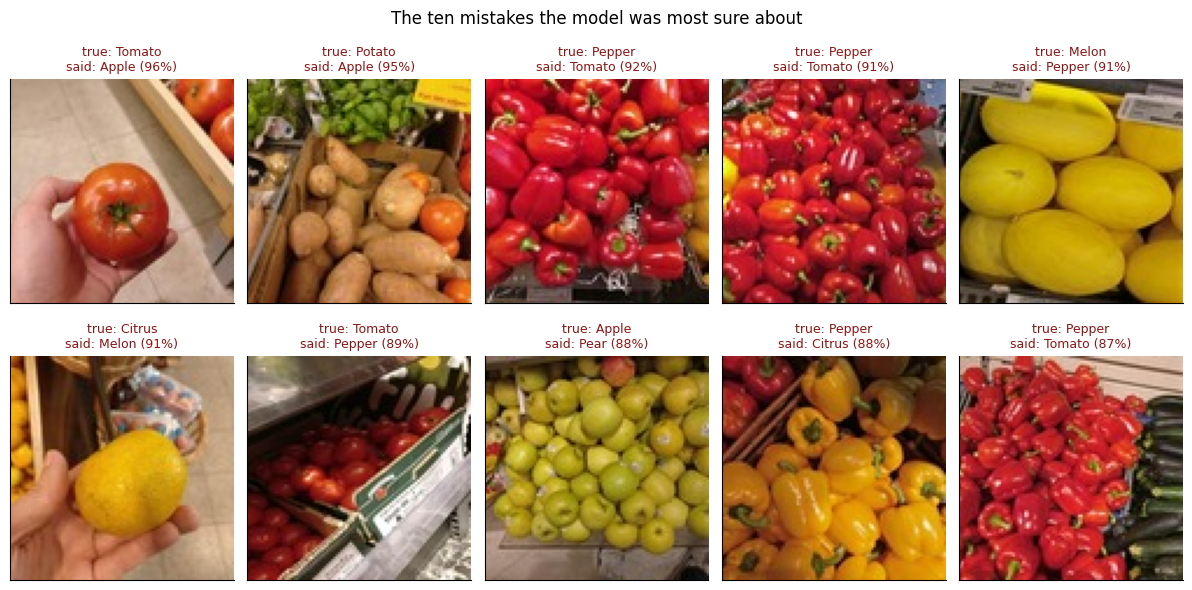

In [ ]:
wrong = np.where(pred != y_test)[0]
worst = wrong[np.argsort(-conf[wrong])][:10]

fig, axes = plt.subplots(2, 5, figsize=(12, 6.0))
for ax, i in zip(axes.ravel(), worst):
    ax.imshow(np.asarray(Image.fromarray(decode(te[i])).resize((96, 96))))
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"true: {CATEGORIES[y_test[i]]}\nsaid: {CATEGORIES[pred[i]]} ({conf[i]:.0%})",
                 fontsize=9, color=MAROON)
fig.suptitle("The ten mistakes the model was most sure about", y=1.00, fontsize=12)
plt.tight_layout(h_pad=3.0); plt.show()

Judge these yourself. Many will be genuinely hard — a green apple photographed beside a
pear, a carton at an angle where the label is invisible. Some are simply bad
photographs.

This is the ceiling of what a small network trained on two thousand images can do. To go
further you need either **more data** or **someone else's data** — which is the next
section.

## 13. Standing on someone else's shoulders: transfer learning

Our network saw 2,195 photographs. **ResNet-18** was trained on ImageNet — 1.2 million
photographs across a thousand categories. It already knows what edges, textures, fruit
skin and cardboard look like.

We can take that network, **freeze everything it learned**, and replace only its final
layer with one that outputs our ten categories. We train that single layer.

This is the single most useful practical technique in applied computer vision, and it is
about five lines of code.

> This step downloads pretrained weights (~45 MB) the first time it runs, so it needs an
> internet connection. If the download is unavailable the notebook prints a notice and
> continues — nothing breaks.

In [ ]:
TRANSFER_OK, acc_transfer, hist_tl = False, None, None
try:
    from torchvision import models
    from torchvision.models import ResNet18_Weights
    backbone = models.resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    TRANSFER_OK = True
    print("Loaded ImageNet-pretrained ResNet-18.")
except Exception as e:
    print("Pretrained weights unavailable in this environment:")
    print(f"  {type(e).__name__}: {str(e)[:110]}")
    print("\nSkipping section 13. Re-run with an internet connection to see it work.")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 102MB/s]


Loaded ImageNet-pretrained ResNet-18.


In [ ]:
if TRANSFER_OK:
    for p in backbone.parameters():          # freeze everything it already knows
        p.requires_grad = False
    backbone.fc = nn.Linear(backbone.fc.in_features, 10)   # new head, trainable

    trainable = n_params(backbone)
    total = sum(p.numel() for p in backbone.parameters())
    print(f"ResNet-18 total parameters      {total:>12,}")
    print(f"Parameters we actually train    {trainable:>12,}  ({trainable/total:.2%})")
    print(f"\nTraining only the final layer for {EPOCHS} epochs\n")
    torch.manual_seed(SEED)
    hist_tl = train(backbone, epochs=EPOCHS, lr=3e-3)
    _, acc_transfer = evaluate(backbone, test_loader)
    print(f"\nTest accuracy: {acc_transfer:.1%}")
else:
    print("Section 13 skipped — no pretrained weights available.")

ResNet-18 total parameters        11,181,642
Parameters we actually train           5,130  (0.05%)

Training only the final layer for 20 epochs

  epoch  1/20   train acc 0.436   val acc 0.599   val loss 1.231
  epoch  2/20   train acc 0.640   val acc 0.680   val loss 0.941
  epoch  3/20   train acc 0.709   val acc 0.693   val loss 0.909
  epoch  4/20   train acc 0.733   val acc 0.715   val loss 0.791
  epoch  5/20   train acc 0.732   val acc 0.748   val loss 0.772
  epoch  6/20   train acc 0.742   val acc 0.722   val loss 0.784
  epoch  7/20   train acc 0.744   val acc 0.741   val loss 0.761
  epoch  8/20   train acc 0.733   val acc 0.718   val loss 0.851
  epoch  9/20   train acc 0.755   val acc 0.715   val loss 0.840
  epoch 10/20   train acc 0.767   val acc 0.712   val loss 0.953
  epoch 11/20   train acc 0.759   val acc 0.748   val loss 0.811
  epoch 12/20   train acc 0.766   val acc 0.741   val loss 0.779
  epoch 13/20   train acc 0.767   val acc 0.741   val loss 0.848
  epoch 14

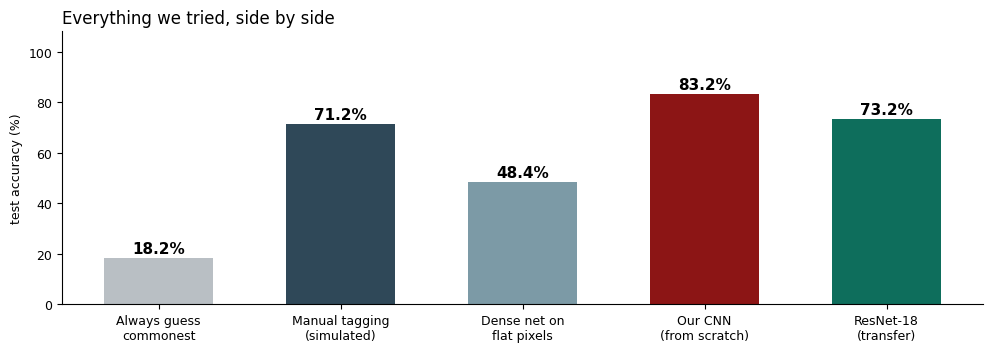

In [ ]:
names = ["Always guess\ncommonest", "Manual tagging\n(simulated)",
         "Dense net on\nflat pixels", "Our CNN\n(from scratch)"]
vals  = [majority, manual_acc, acc_flat, acc_cnn]
cols  = [GREY, SLATE, "#7C9AA6", MAROON]
if TRANSFER_OK:
    names.append("ResNet-18\n(transfer)"); vals.append(acc_transfer); cols.append(TEAL)

fig, ax = plt.subplots(figsize=(10, 3.6))
bars = ax.bar(names, [v*100 for v in vals], color=cols, width=0.6)
ax.set_ylabel("test accuracy (%)"); ax.set_ylim(0, 108)
for b, v in zip(bars, vals):
    ax.text(b.get_x()+b.get_width()/2, v*100+2, f"{v:.1%}",
            ha="center", fontsize=11, fontweight="bold")
ax.set_title("Everything we tried, side by side", loc="left", fontsize=12)
plt.tight_layout(); plt.show()

If the transfer-learning cell ran, look at the gap — and at the cost of getting it.
We trained a **few thousand** parameters instead of a million, for the same number of
epochs, and beat the network we designed ourselves.

**When to use which:**

| | Build from scratch | Transfer learning |
|---|---|---|
| You have | millions of images | hundreds or thousands |
| Your images look like | nothing on the internet (X-rays, satellite, microscopy) | ordinary photographs |
| You need | full control of the architecture | a working model this week |

For a product catalog — ordinary photographs, limited data — transfer learning is almost
always the right first move. We built ours from scratch because **you cannot sensibly
use a tool you do not understand.**

## 14. Save the model

In [ ]:
torch.save({"state_dict": cnn.state_dict(), "categories": CATEGORIES,
            "threshold": float(t_star), "test_accuracy": float(acc_cnn),
            "train_size": TRAIN_SIZE}, "product_cnn.pt")

torch.manual_seed(SEED)
reloaded = ProductCNN().to(DEVICE)
ck = torch.load("product_cnn.pt", map_location=DEVICE, weights_only=False)
reloaded.load_state_dict(ck["state_dict"])
_, a = evaluate(reloaded, test_loader)
print(f"Saved product_cnn.pt — reloaded and verified at {a:.1%}")

Saved product_cnn.pt — reloaded and verified at 83.2%


## Summary

What the pictures in this notebook showed, in order:

1. A photograph is three grids of numbers. Nothing more.
2. Resolution is a trade-off you choose, not a given.
3. Augmentation turns 2,195 photographs into far more, for free.
4. A dense network on flattened pixels works, but plateaus — it was never told the
   pixels formed a picture.
5. A convolutional network, with **one convolution per block** and the depth doubling
   each time, does better with the same effort.
6. The convolutions hold almost none of the parameters and do almost all of the work.
7. Feature maps grow smaller and less recognisable block by block, and **more useful**.
8. The first layer learned colour-opponent and edge filters by itself.
9. Errors concentrate exactly where a human would hesitate.
10. Accuracy is not a decision. A confidence threshold turns a model into a policy.
11. Someone else's pretrained network beats yours, with a fraction of the training.

---

## Exercises

1. **Break the convolution.** Change every `kernel_size=3, padding=1` to
   `kernel_size=1, padding=0`. Each filter now sees one pixel. Retrain and explain the
   drop in one sentence.

2. **Add a fourth block.** Insert `Conv2d(128, 256)` + ReLU + MaxPool, and change the
   head's input to `256*4*4`. Does deeper help here, or do you run out of data first?

3. **Turn augmentation off.** Set `use_aug=False` in the CNN's `train(...)` call. Compare
   the training and validation curves. What exactly went wrong?

4. **Unfreeze the last ResNet block.** In section 13, set `requires_grad = True` for
   `backbone.layer4`. Better? Slower? Worth it?

5. **Move the operating point.** Suppose a human review costs Rs 8 per photograph, and a
   wrong tag costs the lost sales computed in section 3. Write total cost as a function
   of the threshold and find the minimum. Is it the same threshold we chose?

---

